# Development image registartion with simpleElastix

## TODO:

- [x] load data
- [x] test registration
- [x] mask data before registration (black background from rotation)
- [x] obtain suitable and safe masks with the most rotated sample --> should be safe
    - better sample specific mask

In [5]:
#modules
import xarray as xr
import json
import os
import socket
host = socket.gethostname()
import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
    # toppath = '/mnt/SSD/fische_r/COELY'
    
path_01_4D = os.path.join(toppath, '01_rotated_3p1D')
registration_mask_path = os.path.join(gitpath, 'processing', 'masking_for_registration.json')

In [6]:
mask_dimension = json.load(open(registration_mask_path, 'r'))

In [7]:
# jsonpath = os.path.join(gitpath, 'processing', 'masking_for_registration.json')
# with open(jsonpath, "w") as outfile:
    # json.dump(mask_dimension, outfile,indent = 4)
      

## Test: load two operando scans and register

In [8]:
sample = '5II'
file = '01_'+sample+'_rotated_3p1D.nc'
imagepath = os.path.join(path_01_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [9]:
image1 = images[5]
image2 = images[0]

In [10]:
im1 = data[image1].data
im2 = data[image2].data

In [11]:
mask = np.zeros(im1.shape, dtype=np.uint8)
a,b,c,d,e,f = mask_dimension[sample]
mask[a:b,c:d,e:f] = 1 #

In [12]:
data.close()

In [13]:
# a = 30
# b = -30
# c = 30
# d = -10
# e = 30
# f = -30

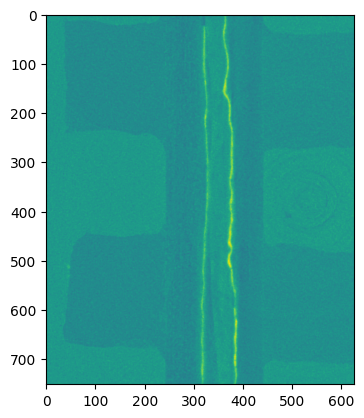

In [14]:
plt.imshow(im1[a:b,c:d,e]) #int(im1.shape[2]/2)

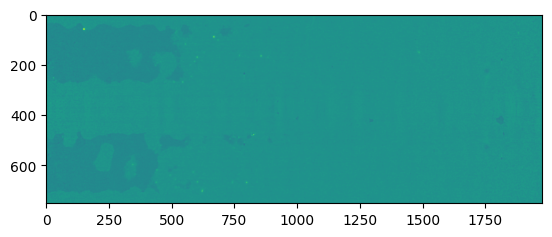

In [15]:
plt.imshow(im1[a:b,d,e:f]) #int(im1.shape[1]/2)

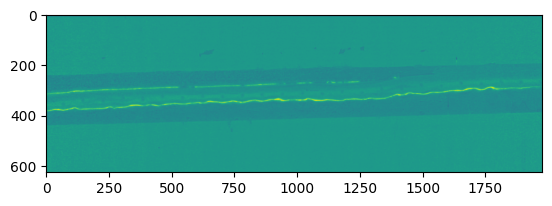

In [16]:
plt.imshow(im1[b,c:d,e:f]) #int(im1.shape[1]/2)

In [17]:
#if ok, save mask dimension
# mask_dimension[sample] = [a, b, c, d, e, f]

In [18]:
# copied from Salvo's and Mayank's code
# TODO: adapat for own purpose, i.e. masking, parallelization, affine registration, transformation matrix
def register_images_general(im_fixed, im_tomove, parameter_map, verbose=False, im_mask=None):

    r"""
    General registration for 2D or 3D images
    This function allows control over the parameter map
    
         
    Parameters
    ----------     
    im_fixed : numpy.ndarray
        Fixed image
    im_tomove: numpy.ndarray
        Image to register (to im_fixed)
    parameter_map: sitk.ParameterMap
        Parameters map object as obtained from sitk.GetParameterMap
    verbose : bool, optional (default=False)
        Enable/Disable log to console 
    im_mask : numpy.ndarray (default=None)
        Mask for sampling points (required). 
        im_mask has same dimensions as im_fixed 
        The mask ndarray has 1 and 0. 1 values denote the area where
        points for the registration are sampled.    
    Returns
    -------
    im_aligned : numpy.ndarray
        Aligned image having same dimensions of im_tomove
                 
    Notes
    -----
    To have further info on parameter maps, go to:
    https://simpleelastix.readthedocs.io/ParameterMaps.html
    For more details on the different parameters, download:
    https://elastix.lumc.nl/download/elastix_manual_v4.8.pdf
    """


    itk_image_fixed = sitk.GetImageFromArray(im_fixed)
    itk_image_tomove = sitk.GetImageFromArray(im_tomove)
           
    elastixImageFilter = sitk.ElastixImageFilter()
    elastixImageFilter.SetFixedImage(itk_image_fixed)
    elastixImageFilter.SetMovingImage(itk_image_tomove)
    elastixImageFilter.SetParameterMap(parameter_map)
    
    if im_mask is not None:
        itk_image_mask = sitk.GetImageFromArray(im_mask)
        # Casting type just in case
        itk_image_mask = sitk.Cast(itk_image_mask, sitk.sitkUInt8)
        elastixImageFilter.SetFixedMask(itk_image_mask)
    
    # Disable/enable logging 
    elastixImageFilter.SetLogToConsole(verbose)
    elastixImageFilter.Execute()

    im_aligned = elastixImageFilter.GetResultImage()
    # Transfor again to numpy
    im_aligned = sitk.GetArrayFromImage(im_aligned)
    return im_aligned

In [19]:
#TODO rigid and affine registration
# TODO: check doc of simpleITK and 3Dslcier to reproduce the settings of Jeremy
##### Parameters for the registration   ################
parameterMap = sitk.GetDefaultParameterMap("rigid") #get default settins for rigid registration

# modify some parameters
parameterMap["FixedImagePyramid"] = ["FixedShrinkingImagePyramid"]
parameterMap["MovingImagePyramid"] = ["MovingShrinkingImagePyramid"]
parameterMap["NumberOfResolutions"] = ["2"]
parameterMap["MaximumNumberOfIterations"] = ["1500"]
parameterMap["AutomaticTransformInitialization"] = ["true"]
parameterMap["AutomaticScalesEstimation"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["Interpolator"] = ["BSplineInterpolator"]
parameterMap["NumberOfSamplesForExactGradient"] = ["10000"]
parameterMap["NumberOfSpatialSamples"] = ["10000"]

In [18]:
im2_aligned = register_images_general(im1,im2, parameterMap, im_mask=mask)

In [27]:
im_fixed = im1
im_tomove = im2
im_mask = mask
parameter_map = parameterMap
verbose = False

In [28]:
itk_image_fixed = sitk.GetImageFromArray(im_fixed)
itk_image_tomove = sitk.GetImageFromArray(im_tomove)
       
elastixImageFilter = sitk.ElastixImageFilter()
elastixImageFilter.SetFixedImage(itk_image_fixed)
elastixImageFilter.SetMovingImage(itk_image_tomove)
elastixImageFilter.SetParameterMap(parameter_map)

if im_mask is not None:
    itk_image_mask = sitk.GetImageFromArray(im_mask)
    # Casting type just in case
    itk_image_mask = sitk.Cast(itk_image_mask, sitk.sitkUInt8)
    elastixImageFilter.SetFixedMask(itk_image_mask)

# Disable/enable logging 
elastixImageFilter.SetLogToConsole(verbose)
elastixImageFilter.Execute()

<SimpleITK.SimpleITK.Image; proxy of <Swig Object of type 'std::vector< itk::simple::Image >::value_type *' at 0x7fb8d0273e40> >

In [30]:
transformParameterMapVector = elastixImageFilter.GetTransformParameterMap()

In [40]:
sitk.WriteParameterFile(elastixImageFilter.GetTransformParameterMap()[0], 'param0.txt')

In [42]:
transformParameterMapVector2 = sitk.ReadParameterFile('param0.txt')

In [31]:
im_aligned = elastixImageFilter.GetResultImage()
# Transfor again to numpy
im_aligned = sitk.GetArrayFromImage(im_aligned)

In [43]:
im_transformed2 = sitk.Transformix(itk_image_tomove, transformParameterMapVector2)

In [44]:
im_transformed2 = sitk.GetArrayFromImage(im_transformed2 )

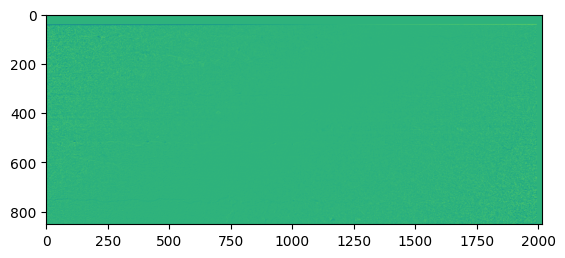

In [45]:
plt.imshow(im_aligned[:,500,:] - im_transformed2[:,500,:])

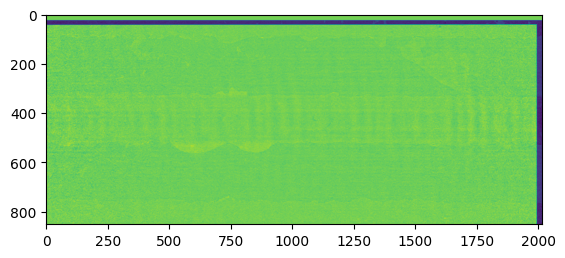

In [46]:
plt.imshow(im_transformed2[:,500,:] - im1[:,500,:])